# Demo: Orquestador Multi-Agente (LangGraph + Gemini)

Este notebook demuestra el **flujo de delegación jerárquico**:

`supervisor → researcher → supervisor → analyst → supervisor (rúbrica) → synthesizer → END`

- **Caso 1:** consulta que requiere investigación externa (Tavily) + análisis (estadísticas y sentimiento).
- **Caso 2:** demostración de la **condición de parada** (`max_steps`) que evita el *supervisor infinito*.

> Cada búsqueda Tavily consume 1 crédito; el guardián limita a 4 búsquedas por ejecución.

In [1]:
from IPython.display import Image, Markdown, display
from graph import graph
from main import run
from tools import credit_guard
from llm import candidate_models

print('Modelos Gemini (principal + fallbacks):', candidate_models())
print(f'Créditos Tavily usados antes de la demo: {credit_guard.credits_used}/{credit_guard.budget}')

Modelos Gemini (principal + fallbacks): ['gemini-3.5-flash', 'gemini-3.6-flash', 'gemini-3.5-flash-lite', 'gemini-3.1-flash-lite']
Créditos Tavily usados antes de la demo: 7/1500


## Topología del grafo

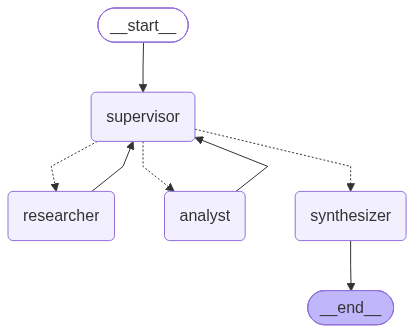

In [2]:
display(Image(graph.get_graph().draw_mermaid_png()))

## Caso 1 — Investigación + Análisis + Síntesis
El supervisor debe delegar primero al **Investigador** (datos con fuentes), luego al **Analista** (cálculos con herramientas) y validar con la rúbrica R1–R5 antes de cerrar.

In [3]:
query = ("Buscá la inflación mensual de Argentina (INDEC) de los últimos 6 meses publicados, calculá el "
         "promedio, la inflación acumulada del período y la tendencia, y analizá el sentimiento de los "
         "titulares de noticias recientes sobre la inflación.")
trace = run(query)


🧑 USUARIO: Buscá la inflación mensual de Argentina (INDEC) de los últimos 6 meses publicados, calculá el promedio, la inflación acumulada del período y la tendencia, y analizá el sentimiento de los titulares de noticias recientes sobre la inflación.



   ⚠️  Modelo gemini-3.5-flash no disponible (Error calling model 'gemini-3.5-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUS). Probando el siguiente...


   ⚠️  Modelo gemini-3.6-flash no disponible (Error calling model 'gemini-3.6-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUS). Probando el siguiente...


🧭 SUPERVISOR [step 1] -> researcher | rúbrica OK=False
   motivo: Ningún especialista ha intervenido aún. Se requiere que el researcher obtenga los datos de inflación mensual del INDEC de los últimos 6 meses y los titulares de noticias recientes antes de que el analyst pueda procesarlos.
   instrucción: Busca la inflación mensual de Argentina publicada por el INDEC de los últimos 6 meses disponibles antes de noviembre de 2026, incluyendo las fuentes (URLs). Además, busca titulares de noticias recientes sobre la inflación en Argentina para poder analizar su sentimiento.


   ⚠️  Modelo gemini-3.5-flash no disponible (Error calling model 'gemini-3.5-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUS). Probando el siguiente...


   ⚠️  Modelo gemini-3.6-flash no disponible (Error calling model 'gemini-3.6-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUS). Probando el siguiente...


... (16 outputs left out)

🧭 SUPERVISOR [step 4] -> FINISH | rúbrica OK=True
   motivo: Se cumplieron los criterios de la rúbrica: el researcher aportó datos con fuentes (R1), el analyst realizó los cálculos correctos sobre los 6 meses publicados posibles considerando la limitación temporal de la fecha de hoy (R2, R3, R5), y la consulta está cubierta abarcando proyecciones y …


   ⚠️  Modelo gemini-3.5-flash no disponible (Error calling model 'gemini-3.5-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUS). Probando el siguiente...


   ⚠️  Modelo gemini-3.6-flash no disponible (Error calling model 'gemini-3.6-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUS). Probando el siguiente...



✅ RESPUESTA FINAL
**1. Respuesta directa**
Dado que la fecha actual es 9 de noviembre de 2026, el dato oficial del INDEC para octubre aún no ha sido publicado, por lo que el análisis numérico se realizó sobre los últimos 5 meses con registros completos (mayo a septiembre de 2026). En dicho período, la inflación mensual promedió un 1,94% y la acumulada alcanzó el 10,08%, mostrando una tendencia general levemente bajista.

**2. Datos clave**
- Mayo 2026: 2,1% (Fuente: *La Voz*)
- Junio 2026: 1,9% (Fuente: *La Voz*)
- Julio 2026: 2,1% (Fuente: *La Voz*)
- Agosto 2026: 1,7% (Fuente: *Datosmacro / INDEC*)
- Septiembre 2026: 1,9% (Fuente: *INDEC*)
- Octubre 2026: N/A - El dato oficial del INDEC se publica el 12 de noviembre de 2026 (Fuente: *Infobae*), con proyecciones privadas entre el 1,8% y el 2%.

**3. Análisis (cálculos y sentimiento)**
- **Promedio (mayo a septiembre):** 1,94%
- **Inflación acumulada (mayo a septiembre):** 10,08%
- **Tendencia:** Bajista, con una pendiente lineal de -

### Trazabilidad del estado compartido
Qué decidió el supervisor en cada paso y qué aportó cada agente:

In [4]:
print('DECISIONES DEL SUPERVISOR')
for d in trace['decisions']:
    print(f"  step {d['step']}: -> {d['next']:<10} rúbrica_ok={d['validation_passed']!s:<5} forzado={d['forced']}")

print('\nCONTRIBUCIONES (state["contributions"])')
for c in trace['contributions']:
    print(f"  [{c['agent']}] step {c['iteration']} | tools={c['tool_calls']} | {len(c['output'])} chars")

DECISIONES DEL SUPERVISOR
  step 1: -> researcher rúbrica_ok=False forzado=False
  step 2: -> analyst    rúbrica_ok=False forzado=False
  step 3: -> researcher rúbrica_ok=False forzado=False
  step 4: -> FINISH     rúbrica_ok=True  forzado=False

CONTRIBUCIONES (state["contributions"])
  [researcher] step 1 | tools=['web_search'] | 1993 chars
  [analyst] step 2 | tools=['compute_statistics', 'sentiment_analysis'] | 1192 chars
  [researcher] step 3 | tools=['web_search'] | 1969 chars


In [5]:
display(Markdown(trace['final_answer']))

**1. Respuesta directa**
Dado que la fecha actual es 9 de noviembre de 2026, el dato oficial del INDEC para octubre aún no ha sido publicado, por lo que el análisis numérico se realizó sobre los últimos 5 meses con registros completos (mayo a septiembre de 2026). En dicho período, la inflación mensual promedió un 1,94% y la acumulada alcanzó el 10,08%, mostrando una tendencia general levemente bajista.

**2. Datos clave**
- Mayo 2026: 2,1% (Fuente: *La Voz*)
- Junio 2026: 1,9% (Fuente: *La Voz*)
- Julio 2026: 2,1% (Fuente: *La Voz*)
- Agosto 2026: 1,7% (Fuente: *Datosmacro / INDEC*)
- Septiembre 2026: 1,9% (Fuente: *INDEC*)
- Octubre 2026: N/A - El dato oficial del INDEC se publica el 12 de noviembre de 2026 (Fuente: *Infobae*), con proyecciones privadas entre el 1,8% y el 2%.

**3. Análisis (cálculos y sentimiento)**
- **Promedio (mayo a septiembre):** 1,94%
- **Inflación acumulada (mayo a septiembre):** 10,08%
- **Tendencia:** Bajista, con una pendiente lineal de -0,06 por período y una desaceleración moderada en el costo de vida.
- **Sentimiento:** Neutral/mixto (score promedio de 0.00), ya que los titulares informan sobre datos estadísticos y expectativas macroeconómicas sin carga subjetiva evidente.

**4. Limitaciones / advertencias**
- **DATOS_INSUFICIENTES:** El valor porcentual exacto de octubre de 2026 no se encuentra disponible en los datos provistos al ser anterior a la fecha de publicación oficial del INDEC (12 de noviembre de 2026). Por este motivo, el análisis de los últimos meses quedó restringido aritméticamente a los 5 meses con registros completos (mayo a septiembre).

## Caso 2 — Condición de parada (anti *supervisor infinito*)
Con `max_steps=2`, el supervisor delega al investigador en el paso 1 y en el paso 2 la regla en código **fuerza `FINISH`** (sin consultar al LLM), aunque falte el análisis. La síntesis declara la limitación.

In [6]:
trace2 = run("Buscá el precio actual del Bitcoin en USD y calculá su variación porcentual de los últimos 7 días.", max_steps=2)
assert trace2['decisions'][-1]['forced'], 'El cierre debió ser forzado'


🧑 USUARIO: Buscá el precio actual del Bitcoin en USD y calculá su variación porcentual de los últimos 7 días.



   ⚠️  Modelo gemini-3.5-flash no disponible (Error calling model 'gemini-3.5-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUS). Probando el siguiente...


   ⚠️  Modelo gemini-3.6-flash no disponible (Error calling model 'gemini-3.6-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUS). Probando el siguiente...


   ⚠️  Modelo gemini-3.5-flash no disponible (Error calling model 'gemini-3.5-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUS). Probando el siguiente...


🧭 SUPERVISOR [step 1] -> researcher | rúbrica OK=False
   motivo: Ningún especialista ha intervenido. Se necesita que el researcher obtenga los datos actuales e históricos necesarios para que el analyst pueda hacer el cálculo posterior.
   instrucción: Buscá el precio actual del Bitcoin en USD y los datos históricos de precios diarios de los últimos 7 días con sus respectivas fuentes (URLs).


   ⚠️  Modelo gemini-3.6-flash no disponible (Error calling model 'gemini-3.6-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUS). Probando el siguiente...



🔎 RESEARCHER (tools: web_search, web_search)
   ## Hallazgos - Precio actual del Bitcoin (BTC) en USD: entre $74,165.40 (Investing.com) y $77,396.10 (CoinGlass), con referencias cercanas en $75,782.68 (Coinbase) a la fecha del 9 de noviembre de 2026. (fuente: https://www.coinbase.com/price/bitcoin, https://www.coinglass.com/currencies/BTC, https://www.investing.com/crypto/bitcoin/historical-data) - Datos históricos de precios diarios de los últimos 7 días (del 2 de noviembre de 2026 al 8 de noviembre de 2026, según registros de Yahoo Finance / BTC-USD): - Nov 2, 2026: Cierre de $76,677.30 (Apertura: $78,248.45, Alto: $78,724.39, Bajo: $76,572.23) (fuente: https://finance.yahoo.com/quote/BTC-USD/history) - Nov 3, 2026: Cierre de $77,345.05 (Apertura: $76,677.30, Alto: $77,964.98, Bajo: $76,270.00) (fuente: https://finance.yahoo.com/quote/BTC-USD/history) - Nov 4, 2026: Cierre de $80,056.22 (Apertura: $77,338.23, Alto: $80,746.25, … 

🧭 SUPERVISOR [step 2] -> FINISH (FORZADO) | rúbrica 

   ⚠️  Modelo gemini-3.5-flash no disponible (Error calling model 'gemini-3.5-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUS). Probando el siguiente...


   ⚠️  Modelo gemini-3.6-flash no disponible (Error calling model 'gemini-3.6-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUS). Probando el siguiente...



✅ RESPUESTA FINAL
1. **Respuesta directa**
El precio actual del Bitcoin en USD se ubica entre $74,165.40 y $77,396.10, con una referencia cercana de $75,782.68 al 9 de noviembre de 2026. Su variación porcentual en los últimos 7 días muestra una tendencia a la baja que oscila entre un -2% y un -5.05%, según la plataforma consultada.

2. **Datos clave**
- **Precio actual de Bitcoin (Coinbase):** $75,782.68 USD *(Fuente: https://www.coinbase.com/price/bitcoin)*
- **Precio actual de Bitcoin (CoinGlass):** $77,396.10 USD *(Fuente: https://www.coinglass.com/currencies/BTC)*
- **Precio actual de Bitcoin (Investing.com):** $74,165.40 USD *(Fuente: https://www.investing.com/crypto/bitcoin/historical-data)*
- **Cierre 2 de noviembre de 2026:** $76,677.30 USD *(Fuente: https://finance.yahoo.com/quote/BTC-USD/history)*
- **Cierre 3 de noviembre de 2026:** $77,345.05 USD *(Fuente: https://finance.yahoo.com/quote/BTC-USD/history)*
- **Cierre 4 de noviembre de 2026:** $80,056.22 USD *(Fuente: https:

In [7]:
print(f'Créditos Tavily usados después de la demo: {credit_guard.credits_used}/{credit_guard.budget}')

Créditos Tavily usados después de la demo: 12/1500
